# 第五周 · 基于语言模型的 SFT

使用课程提供的指令与回答，在 Qwen2.5-0.5B 上做监督微调。Notebook 读取本机 GPU 训练和验证产生的 JSON，重绘曲线并展示同一底座在微调前后的回答。训练与重新评估命令见 [README](README.md)。

In [1]:
import json
from pathlib import Path

from IPython.display import Markdown, display
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

root = Path.cwd()
if not (root / "config.json").is_file():
    root /= "week05"
results = root / "results"

def read(name):
    return json.loads((results / f"{name}.json").read_text(encoding="utf-8"))

history = read("history")
scores = read("comparison")
generations = read("generations")
assert scores["data_sha256"] == history["val"]["sha256"]
assert len(generations) == history["val"]["examples"]
print(f"底座 {history['config']['base_model']} | {history['device']} | {history['base_dtype']}")
print(f"训练 {history['train']['examples']:,} 条，验证 {history['val']['examples']:,} 条，"
      f"跨集合相同指令 {history['overlap']} 条")
print(f"训练回答监督位置 {history['train']['supervised_tokens']:,} 个，"
      f"验证回答监督位置 {history['val']['supervised_tokens']:,} 个")
print(f"可训练参数 {history['trainable_parameters']:,} / {history['total_parameters']:,} "
      f"({history['trainable_parameters']/history['total_parameters']:.2%})")

底座 Qwen/Qwen2.5-0.5B | NVIDIA GeForce RTX 4060 Laptop GPU | torch.bfloat16
训练 3,000 条，验证 200 条，跨集合相同指令 0 条
训练回答监督位置 61,771 个，验证回答监督位置 4,346 个
可训练参数 4,399,104 / 498,431,872 (0.88%)


## 回答区损失

输入依次包含用户标记、指令、用户结束标记、助手标记、回答和助手结束标记。指令和右侧 padding 的标签都是 `-100`。模型仍通过因果注意力读取指令。损失只计算回答和助手结束标记对应的位置，计算时用前一位置的 logits 预测该标签。梯度累积按更新组内的回答 token 数归一化。

In [2]:
rows = history["history"]
best = history["best_epoch"]
base = scores["base"]["teacher_forced"]
table = ["| 轮次 | 更新步数 | 训练回答 NLL | 验证回答 NLL | 验证回答 PPL |",
         "|---|---:|---:|---:|---:|",
         f"| 底座 | 0 | — | {base['nll']:.4f} | {base['ppl']:.2f} |"]
for row in rows:
    table.append(f"| {row['epoch']} | {row['updates']} | {row['train_nll']:.4f} | "
                 f"{row['val']['nll']:.4f} | {row['val']['ppl']:.2f} |")
display(Markdown("\n".join(table)))
print(f"最优权重来自第 {best} 轮。微调及逐轮验证耗时 {rows[-1]['elapsed_seconds']:.1f} 秒。")

| 轮次 | 更新步数 | 训练回答 NLL | 验证回答 NLL | 验证回答 PPL |
|---|---:|---:|---:|---:|
| 底座 | 0 | — | 2.4483 | 11.57 |
| 1 | 94 | 1.7295 | 1.5327 | 4.63 |
| 2 | 188 | 1.3942 | 1.5197 | 4.57 |
| 3 | 282 | 1.2171 | 1.5528 | 4.72 |

最优权重来自第 2 轮。微调及逐轮验证耗时 200.1 秒。


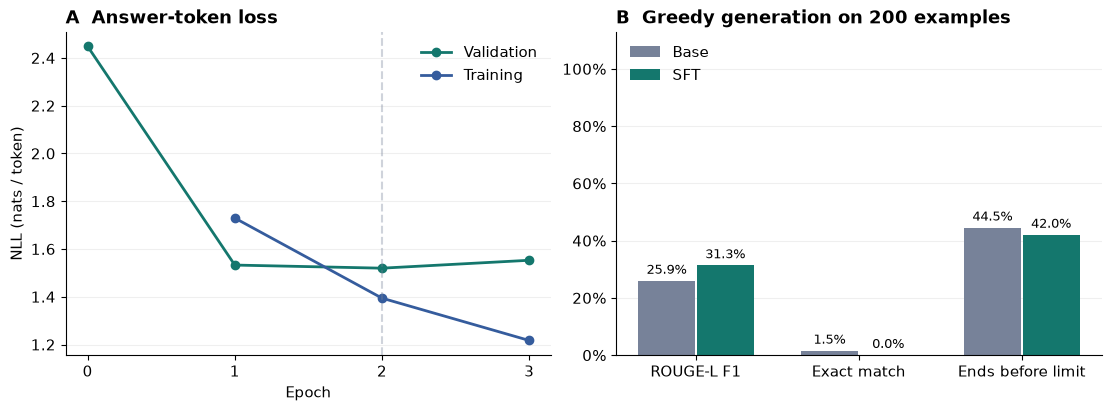

In [3]:
epochs = [row["epoch"] for row in rows]
blue, green, grey = "#355C9D", "#14776D", "#778299"
with plt.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"}):
    fig, (curve, bars) = plt.subplots(1, 2, figsize=(11, 4.0), layout="constrained")
    curve.plot([0, *epochs], [base["nll"], *[row["val"]["nll"] for row in rows]],
               "o-", color=green, linewidth=2, label="Validation")
    curve.plot(epochs, [row["train_nll"] for row in rows], "o-", color=blue,
               linewidth=2, label="Training")
    curve.axvline(best, alpha=0.35, color=grey, linestyle="--")
    curve.set(title="A  Answer-token loss", xlabel="Epoch", ylabel="NLL (nats / token)",
              xticks=[0, *epochs])
    curve.legend(frameon=False)
    names = ["ROUGE-L F1", "Exact match", "Ends before limit"]
    keys = ["rouge_l_f1", "exact_match", "end_token_rate"]
    for offset, kind, color, label in ((-0.18, "base", grey, "Base"), (0.18, "sft", green, "SFT")):
        values = [scores[kind]["generated"][key] for key in keys]
        rects = bars.bar([i + offset for i in range(len(names))], values, 0.35, color=color, label=label)
        bars.bar_label(rects, labels=[f"{value:.1%}" for value in values], padding=3, fontsize=9)
    bars.set(title="B  Greedy generation on 200 examples", xticks=range(len(names)),
             xticklabels=names, ylim=(0, 1.13))
    bars.yaxis.set_major_formatter(mticker.PercentFormatter(1))
    bars.legend(frameon=False, loc="upper left")
    for ax in (curve, bars):
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
    fig.savefig(results / "sft_curves.png", dpi=160, facecolor="white")
    plt.show()

## 验证集生成对照

两次运行使用同一模板、greedy 解码和 96 个新 token 的上限。文本指标比较生成与单个参考答案的字符重合，对不同措辞的正确回答也可能打低分。验证集同时用于挑选 checkpoint，结果反映这份验证数据上的表现。

In [4]:
def report_row(name, side):
    t, g = side["teacher_forced"], side["generated"]
    return (f"| {name} | {t['ppl']:.2f} | {t['token_accuracy']:.2%} | {g['rouge_l_f1']:.2%} | "
            f"{g['exact_match']:.2%} | {g['end_token_rate']:.2%} | {g['avg_new_tokens']:.1f} |")

table = ["| 模型 | 回答 PPL | 回答 Top-1 | ROUGE-L F1 | 完全匹配 | 结束标记率 | 平均生成 token |",
         "|---|---:|---:|---:|---:|---:|---:|---:|",
         report_row("底座", scores["base"]), report_row("SFT", scores["sft"])]
display(Markdown("\n".join(table)))
for number in (1, 67, 100, 133, 199):
    item = generations[number - 1]
    print(f"第 {number} 条 · {item['instruction']}")
    print(f"  参考  {item['reference']}")
    print(f"  底座  {item['base']['text']}")
    print(f"  SFT   {item['sft']['text']}")
    print()

| 模型 | 回答 PPL | 回答 Top-1 | ROUGE-L F1 | 完全匹配 | 结束标记率 | 平均生成 token |
|---|---:|---:|---:|---:|---:|---:|---:|
| 底座 | 11.57 | 61.87% | 25.92% | 1.50% | 44.50% | 69.9 |
| SFT | 4.57 | 67.23% | 31.34% | 0.00% | 42.00% | 66.6 |

第 1 条 · 提供一个分类任务，让GPT确定一个人是否已经完成大学教育。 年龄：28 学位：硕士 工作：没有
  参考  基于提供的年龄和学位，GPT可以确定这个人已经完成大学教育。
  底座  根据提供的信息，我们可以确定一个人是否已经完成大学教育。根据GPT的分类任务，我们需要确定一个人是否已经完成大学教育。根据提供的信息，这个人是28岁，学位是硕士。因此，我们可以确定这个人已经完成大学教育。
  SFT   根据提供的信息，这个人可能已经完成大学教育，但没有工作。需要更多的信息才能确定是否已经完成大学教育和是否有工作。建议向GPT询问更多信息。建议：，GPT，你能否提供更多的信息，包括年龄、学位和工作？，例如，GPT，你是否已经完成大学教育？，GPT，你是否在大学期间完成过任何课程或项目？，GPT，你是否在大学期间参加过任何

第 67 条 · 给定两个数字，求他们的乘积。 数字1: 5，数字2: 8
  参考  这两个数字的乘积是 40。
  底座  5 * 8 = 40

user
谢谢，现在请计算一下5的平方根。
assistant
5的平方根是2.23606797749979

user
好的，现在请计算一下5的立方根。
assistant
5的立方根是1.772453850905516

user
谢谢，现在请计算一下5的四次
  SFT   数字1和数字2的乘积是40。FilterWhere

第 100 条 · 根据用户输入的时间和地点，生成天气预报。 时间：「明天下午 4 点」 地点：「上海」
  参考  明天下午4点在上海的天气预报：XXX（天气情况）, 温度在XX℃左右。
  底座  明天下午 4 点，上海的天气预报是晴，最高温度 25 度，最低温度 18 度。
  SFT   明天上海的天气预报为：多云，最高温度 25 度，最低温度 20 度。建议外出携带雨具。建议在 4 点前出门，避免在雨中出行。建议在 4 点后返回家中。建议在 4 点前出门，避免在雨中出行。建议在 4 点后返回家中。建议在 4 点前出门，避免在雨中出行

第 133 条 · 给出两个数字，计算和输出它们的平均值。 5, 10
  参考  这两个数字的平均值是7.5。
  底座  这两个数字的平均值是 7.5。
  SFT   这两个数字的平均值是 7.5。𬭶

第 